<a href="https://colab.research.google.com/github/SUZAN1010/502AZ-formative-task-1./blob/main/Week2_formative_assignment_task_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
##Load the datasets
import pandas as pd

student_path = "/student_dropout_dataset_v3.csv"
wholesale_path = "/Wholesale customers data.csv"

student = pd.read_csv(student_path)
wholesale = pd.read_csv(wholesale_path)

print("Student dataset", student.shape)
print("Wholesale dataset", wholesale.shape)
student.head()

Student dataset (10000, 19)
Wholesale dataset (440, 8)


,Student_ID,Age,Gender,Family_Income,Internet_Access,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Part_Time_Job,Scholarship,Stress_Index,GPA,Semester_GPA,CGPA,Semester,Department,Parental_Education,Dropout
0,1,22.1,Male,25000.0,Yes,3.36,86.1,2,20.4,Yes,No,5.5,0.96,0.90,0.90,Year 1,Arts,High School,0
1,2,20.7,Male,25000.0,Yes,4.30,68.0,2,44.0,No,No,6.8,1.28,1.20,1.19,Year 3,Engineering,Bachelor,1
2,3,22.4,Male,40183.0,Yes,4.40,70.9,0,48.9,Yes,No,5.5,1.68,1.32,1.32,Year 1,Arts,Master,0
3,4,24.4,Male,NaN,Yes,NaN,82.2,2,38.6,No,No,NaN,1.78,1.77,1.77,Year 1,CS,High School,1
4,5,20.5,Female,25319.0,Yes,4.19,75.7,1,23.0,No,No,7.0,1.48,0.91,0.87,Year 4,Business,Bachelor,0


In [23]:
## Count missing values
student_missing = student.isna().sum()
wholesale_missing = wholesale.isna().sum()

print("Student columns with missing values")
print(student_missing[student_missing > 0])

print("\nTotal missing values in the wholesale dataset")
print(wholesale_missing.sum())

Student columns with missing values
Family_Income          500
Study_Hours_per_Day    500
Stress_Index           500
Parental_Education     511
dtype: int64

Total missing values in the wholesale dataset
0


In [24]:
## Inspect the orginal education labels
education_raw = pd.read_csv(
    student_path,
    usecols=["Parental_Education"],
    keep_default_na=False
)

print(education_raw["Parental_Education"].value_counts())

Parental_Education
Bachelor       3949
High School    3072
Master         2003
None            511
PhD             465
Name: count, dtype: int64


In [25]:
##Restore the None catrgory
student["Parental_Education"] = education_raw["Parental_Education"]

student_missing = student.isna().sum()
print(student_missing[student_missing > 0])

Family_Income          500
Study_Hours_per_Day    500
Stress_Index           500
dtype: int64


In [26]:
## Summarise numarical features
student_numeric = student.select_dtypes(include="number").drop(
    columns=["Student_ID", "Dropout"]
)

spending_columns = [
    "Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"
]

print("Student numerical features")
print(student_numeric.describe().T.round(2).to_string())

print("\nWholesale spending")
print(wholesale[spending_columns].describe().T.round(2).to_string())

Student numerical features
                         count      mean       std      min       25%       50%       75%        max
Age                    10000.0     21.03      2.14     17.0     19.50     21.00     22.50      29.60
Family_Income           9500.0  38377.25  20496.23  25000.0  25000.00  29740.50  44520.00  316601.00
Study_Hours_per_Day     9500.0      4.01      1.30      0.5      3.16      4.00      4.87       8.98
Attendance_Rate        10000.0     81.74      8.22     38.2     76.40     81.80     87.30     100.00
Assignment_Delay_Days  10000.0      1.80      1.34      0.0      1.00      2.00      3.00       8.00
Travel_Time_Minutes    10000.0     30.18     11.92      5.0     21.90     30.20     38.40      74.90
Stress_Index            9500.0      5.51      1.77      1.0      4.30      5.50      6.70      10.00
GPA                    10000.0      2.31      1.06      0.0      1.55      2.35      3.12       4.00
Semester_GPA           10000.0      2.30      1.07      0.0     

In [27]:
##Count categories
print("Student dropout counts")
print(student["Dropout"].value_counts().sort_index())

print("\nStudent dropout percentages")
print(student["Dropout"].value_counts(normalize=True).sort_index().mul(100).round(2))

print("\nParental education counts")
print(student["Parental_Education"].value_counts())

print("\nWholesale channel counts")
print(wholesale["Channel"].value_counts().sort_index())

print("\nWholesale region counts")
print(wholesale["Region"].value_counts().sort_index())

Student dropout counts
Dropout
0    7646
1    2354
Name: count, dtype: int64

Student dropout percentages
Dropout
0    76.46
1    23.54
Name: proportion, dtype: float64

Parental education counts
Parental_Education
Bachelor       3949
High School    3072
Master         2003
None            511
PhD             465
Name: count, dtype: int64

Wholesale channel counts
Channel
1    298
2    142
Name: count, dtype: int64

Wholesale region counts
Region
1     77
2     47
3    316
Name: count, dtype: int64


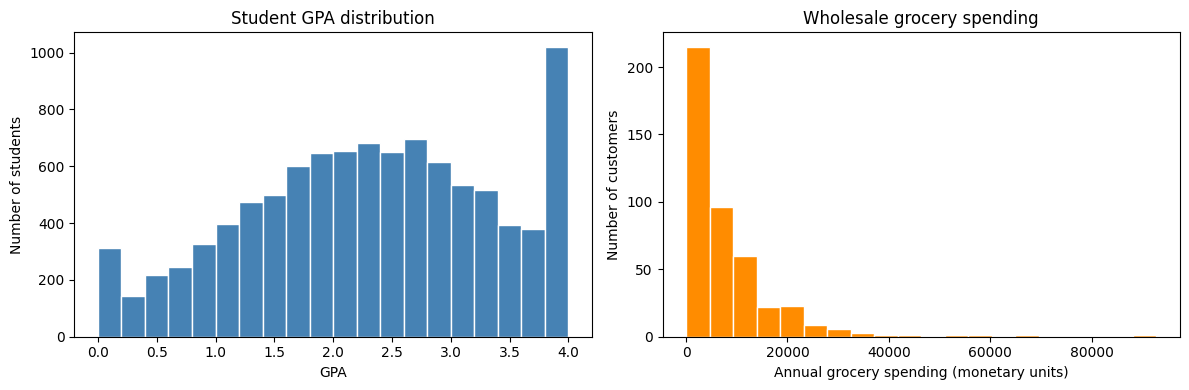

In [28]:
## Plot the distributions
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(student["GPA"], bins=20, color="steelblue", edgecolor="white")
axes[0].set_title("Student GPA distribution")
axes[0].set_xlabel("GPA")
axes[0].set_ylabel("Number of students")

axes[1].hist(wholesale["Grocery"], bins=20, color="darkorange", edgecolor="white")
axes[1].set_title("Wholesale grocery spending")
axes[1].set_xlabel("Annual grocery spending (monetary units)")
axes[1].set_ylabel("Number of customers")

plt.tight_layout()
plt.show()

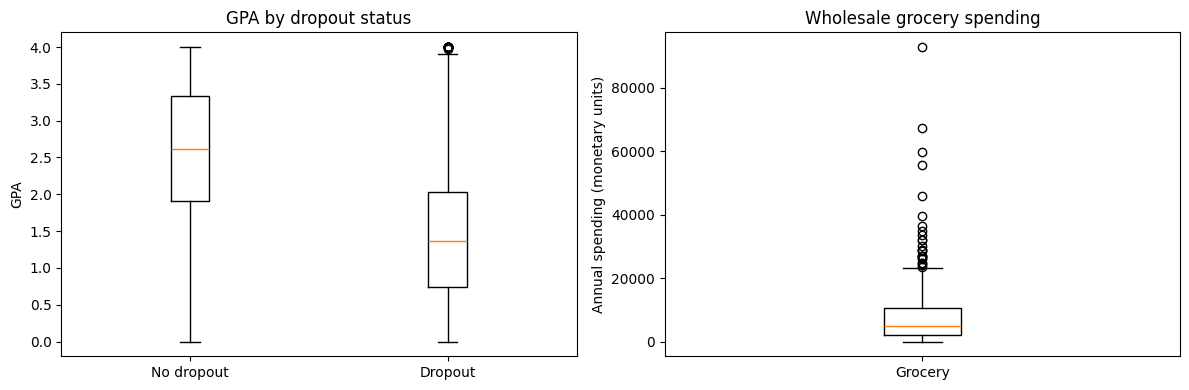

Median GPA (no dropout): 2.62
Median GPA (dropout): 1.37


In [29]:
## Compare distributions with box plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

no_dropout_gpa = student.loc[student["Dropout"] == 0, "GPA"].dropna()
dropout_gpa = student.loc[student["Dropout"] == 1, "GPA"].dropna()

axes[0].boxplot([no_dropout_gpa, dropout_gpa])
axes[0].set_xticks([1, 2], ["No dropout", "Dropout"])
axes[0].set_title("GPA by dropout status")
axes[0].set_ylabel("GPA")

axes[1].boxplot(wholesale["Grocery"].dropna())
axes[1].set_xticks([1], ["Grocery"])
axes[1].set_title("Wholesale grocery spending")
axes[1].set_ylabel("Annual spending (monetary units)")

plt.tight_layout()
plt.show()

print("Median GPA (no dropout):", round(no_dropout_gpa.median(), 2))
print("Median GPA (dropout):", round(dropout_gpa.median(), 2))

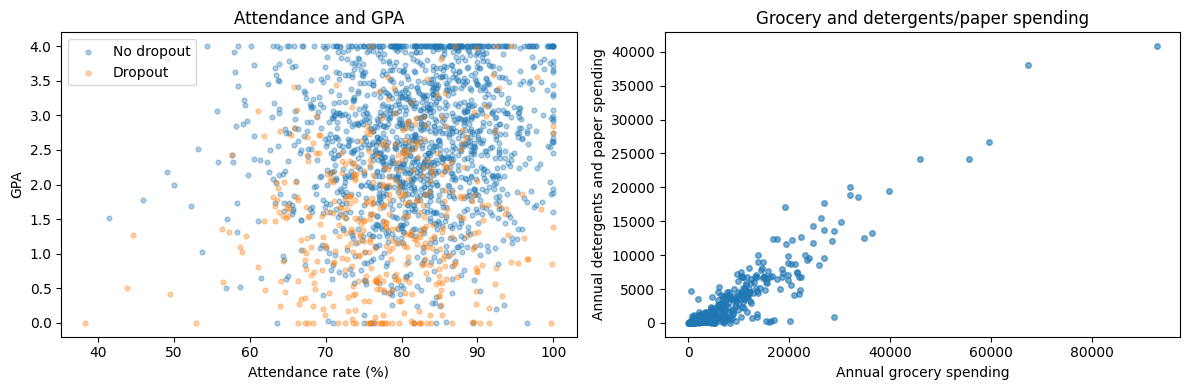

In [30]:
## Explore relationships with scatter plots
student_sample = student.sample(n=2000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for dropout_code, label in [(0, "No dropout"), (1, "Dropout")]:
    group = student_sample[student_sample["Dropout"] == dropout_code]
    axes[0].scatter(
        group["Attendance_Rate"], group["GPA"],
        s=12, alpha=0.35, label=label
    )

axes[0].set_title("Attendance and GPA")
axes[0].set_xlabel("Attendance rate (%)")
axes[0].set_ylabel("GPA")
axes[0].legend()

axes[1].scatter(
    wholesale["Grocery"], wholesale["Detergents_Paper"],
    s=16, alpha=0.6
)
axes[1].set_title("Grocery and detergents/paper spending")
axes[1].set_xlabel("Annual grocery spending")
axes[1].set_ylabel("Annual detergents and paper spending")

plt.tight_layout()
plt.show()

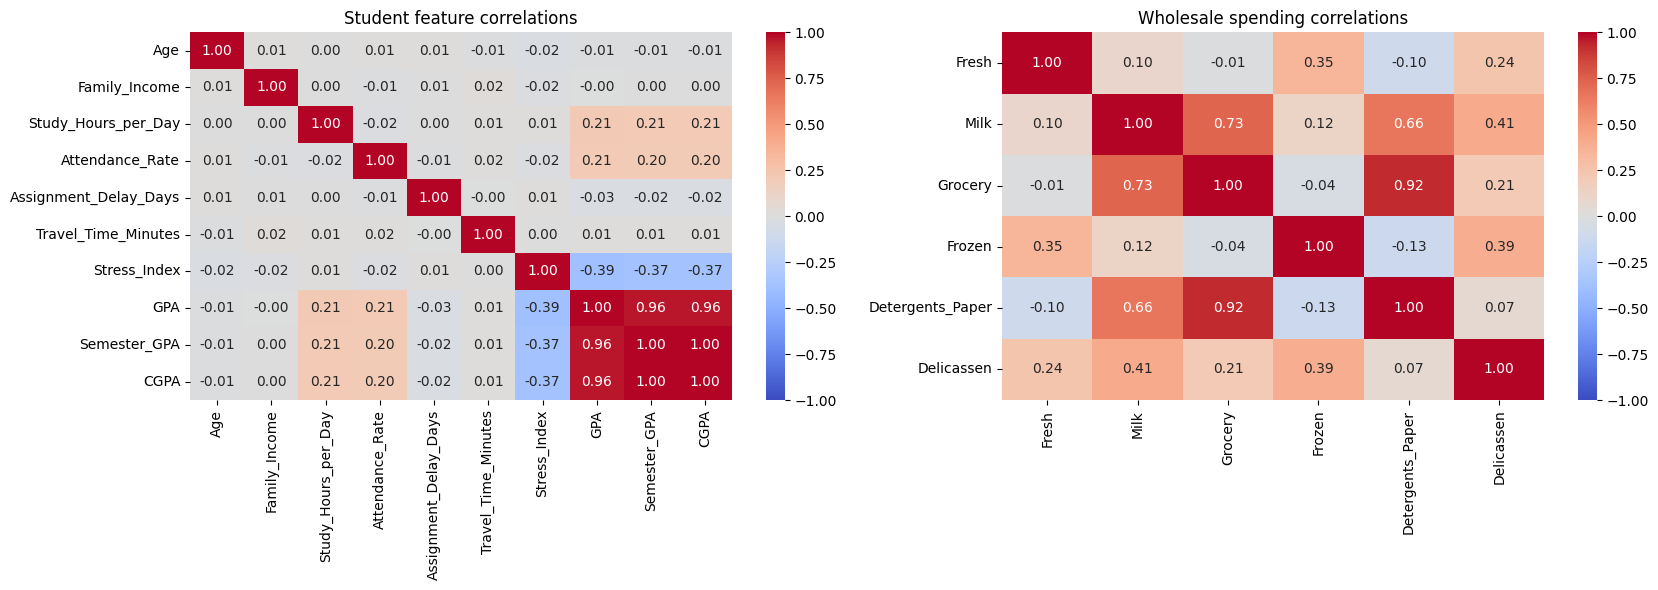

In [31]:
# Compare Pearson correlations between student numerical features and between the six wholesale spending categories.
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

sns.heatmap(
    student_numeric.corr(), annot=True, fmt=".2f",
    cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0]
)
axes[0].set_title("Student feature correlations")

sns.heatmap(
    wholesale[spending_columns].corr(), annot=True, fmt=".2f",
    cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1]
)
axes[1].set_title("Wholesale spending correlations")

plt.tight_layout()
plt.show()

In [32]:
# Split the student records into training and test sets.
# Learn how to fill, scale, and encode the features from the training set.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = student.drop(columns=["Student_ID", "Dropout"])
y = student["Dropout"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_columns = X_train.select_dtypes(include="number").columns
category_columns = X_train.select_dtypes(exclude="number").columns

preprocessor = ColumnTransformer([
    ("numeric", make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler()
    ), numeric_columns),
    ("categorical", OneHotEncoder(
        handle_unknown="ignore", sparse_output=False
    ), category_columns)
])

student_train_ready = preprocessor.fit_transform(X_train)
student_test_ready = preprocessor.transform(X_test)

print("Training shape:", student_train_ready.shape)
print("Test shape:", student_test_ready.shape)
print("Missing training values:", pd.isna(student_train_ready).sum())
print("Missing test values:", pd.isna(student_test_ready).sum())

Training shape: (8000, 32)
Test shape: (2000, 32)
Missing training values: 0
Missing test values: 0


In [33]:
# Reduce skew in the six spending columns, then scale them for clustering.
import numpy as np

raw_spending = wholesale[spending_columns]
log_spending = np.log1p(raw_spending)

wholesale_scaler = StandardScaler()
wholesale_ready = pd.DataFrame(
    wholesale_scaler.fit_transform(log_spending),
    columns=spending_columns,
    index=wholesale.index
)

print("Wholesale shape:", wholesale_ready.shape)
print("Missing values:", wholesale_ready.isna().sum().sum())

comparison = pd.DataFrame({
    "Original skew": raw_spending.skew(),
    "Skew after log": log_spending.skew(),
    "Scaled mean": wholesale_ready.mean(),
    "Scaled standard deviation": wholesale_ready.std(ddof=0)
})

print(comparison.round(3).to_string())

Wholesale shape: (440, 6)
Missing values: 0
                  Original skew  Skew after log  Scaled mean  Scaled standard deviation
Fresh                     2.561          -1.575          0.0                        1.0
Milk                      4.054          -0.224         -0.0                        1.0
Grocery                   3.587          -0.675         -0.0                        1.0
Frozen                    5.908          -0.353          0.0                        1.0
Detergents_Paper          3.632          -0.236         -0.0                        1.0
Delicassen               11.152          -1.092         -0.0                        1.0


In [34]:
# Save the prepared student splits and wholesale spending table as CSV files.
feature_names = preprocessor.get_feature_names_out()

student_train_export = pd.DataFrame(
    student_train_ready, columns=feature_names, index=y_train.index
)
student_test_export = pd.DataFrame(
    student_test_ready, columns=feature_names, index=y_test.index
)

student_train_export["Dropout"] = y_train
student_test_export["Dropout"] = y_test

student_train_export.to_csv("student_train_preprocessed.csv", index=False)
student_test_export.to_csv("student_test_preprocessed.csv", index=False)
wholesale_ready.to_csv("wholesale_spending_preprocessed.csv", index=False)

print("Student training CSV:", student_train_export.shape)
print("Student test CSV:", student_test_export.shape)
print("Wholesale CSV:", wholesale_ready.shape)

Student training CSV: (8000, 33)
Student test CSV: (2000, 33)
Wholesale CSV: (440, 6)


## Conclusion
The student dataset shows that the dropout had a lower median GPS(1.37) than the non-droupout group (2.62). In the wholesale dataset, grocery spending and detergents and paper spending had a strong positive correlations(r=0.92).
I split the student data into 8000 training records and 2000 test records. I use the training data to learn how to fill missing numarical values, scale the numarical features, and encode categories, then applied the same rule to the test data. Neither prepared split had messing values.
For the wholesale dataset, I applied a log transformation to reduce skew and then standardised the six spending features. The prepared dataset contained all 440 customers.

Dataset shape: (10000, 19)
Rows with missing values: 500 (5.0%)
Exact duplicate rows: 0
Repeated student IDs: 0


,Data type,Missing values
Student_ID,int64,0
Age,float64,0
Gender,object,0
Family_Income,float64,500
Internet_Access,object,0
Study_Hours_per_Day,float64,500
Attendance_Rate,float64,0
Assignment_Delay_Days,int64,0
Travel_Time_Minutes,float64,0
Part_Time_Job,object,0


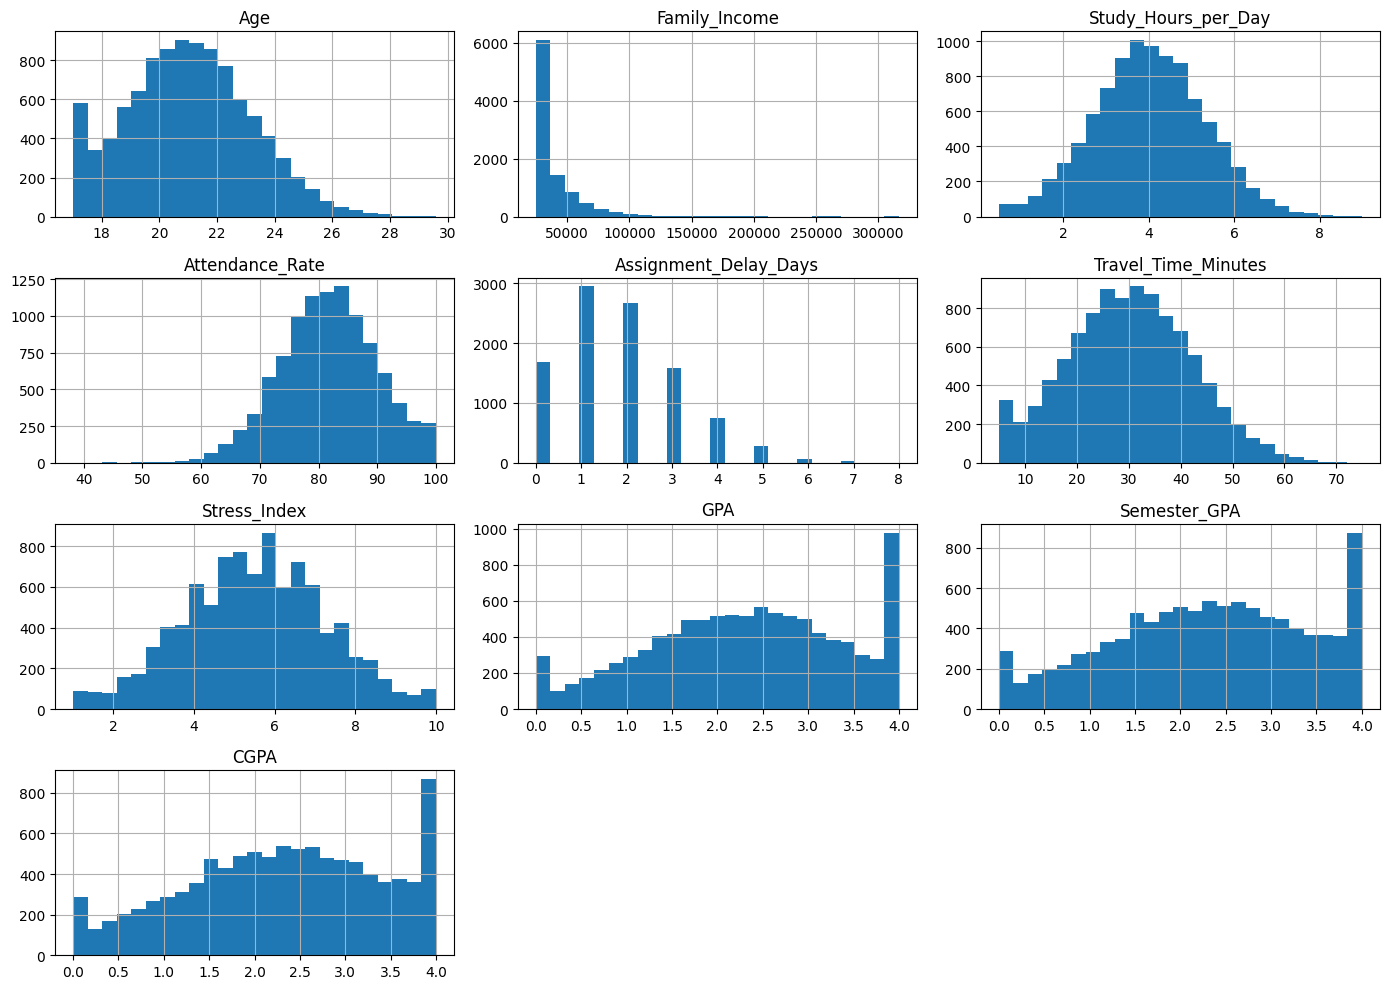

,Minimum,Maximum,Skewness,Potential outliers
Age,17.0,29.60,0.18,33
Family_Income,25000.0,316601.00,2.83,604
Study_Hours_per_Day,0.5,8.98,0.03,86
Attendance_Rate,38.2,100.00,-0.17,57
Assignment_Delay_Days,0.0,8.00,0.70,25
Travel_Time_Minutes,5.0,74.90,0.09,25
Stress_Index,1.0,10.00,-0.01,0
GPA,0.0,4.00,-0.20,0
Semester_GPA,0.0,4.00,-0.22,0
CGPA,0.0,4.00,-0.22,0


Correlation among grade features:


,GPA,Semester_GPA,CGPA
GPA,1.000,0.964,0.963
Semester_GPA,0.964,1.000,0.999
CGPA,0.963,0.999,1.000


In [35]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the CSV. Keep "None" as a category and treat empty fields as missing.
student_eda = pd.read_csv(
    student_path,
    keep_default_na=False,
    na_values=[""]
)

# Check data types, missing values, and duplicates.
missing_rows = student_eda.isna().any(axis=1)

print("Dataset shape:", student_eda.shape)
print(f"Rows with missing values: {missing_rows.sum()} ({missing_rows.mean():.1%})")
print("Exact duplicate rows:", student_eda.duplicated().sum())
print("Repeated student IDs:", student_eda["Student_ID"].duplicated().sum())

display(pd.DataFrame({
    "Data type": student_eda.dtypes,
    "Missing values": student_eda.isna().sum()
}))

# Select numerical predictors, excluding the ID and target.
numeric = student_eda.drop(
    columns=["Student_ID", "Dropout"]
).select_dtypes(include="number")

# Plot a histogram for each numerical predictor.
numeric.hist(bins=25, figsize=(14, 10))
plt.tight_layout()
plt.show()

# Flag potential outliers using the 1.5 × IQR rule.
q1 = numeric.quantile(0.25)
q3 = numeric.quantile(0.75)
iqr = q3 - q1

outliers = numeric.lt(q1 - 1.5 * iqr) | numeric.gt(q3 + 1.5 * iqr)

display(pd.DataFrame({
    "Minimum": numeric.min(),
    "Maximum": numeric.max(),
    "Skewness": numeric.skew().round(2),
    "Potential outliers": outliers.sum()
}))

# Compare GPA, Semester GPA, and CGPA.
print("Correlation among grade features:")
display(student_eda[["GPA", "Semester_GPA", "CGPA"]].corr().round(3))

In [36]:
wholesale_categories_encoded = pd.get_dummies(
    wholesale[["Channel", "Region"]],
    columns=["Channel", "Region"],
    dtype=int
)

print(wholesale_categories_encoded.head().to_string(index=False))

 Channel_1  Channel_2  Region_1  Region_2  Region_3
         0          1         0         0         1
         0          1         0         0         1
         0          1         0         0         1
         1          0         0         0         1
         0          1         0         0         1


### What the results show

The Student Dropout dataset contains 10,000 records and 19 columns. A total of 500 students (5.0%) had missing values. The same 500 records were missing Family Income, Study Hours per Day, and Stress Index. I found no duplicate rows or repeated student IDs.

Family Income was strongly right-skewed (skewness = 2.83). The IQR rule flagged 604 income values for review. High incomes can be valid, so I would check them before deciding whether to remove any values.

Semester GPA and CGPA were very strongly correlated (r = 0.999). For a future model, I would test whether keeping only one of these features gives similar results.

To prepare the data, I would fill the missing numerical values with medians calculated from the training set, standardise the numerical predictors, and one-hot encode the categorical predictors.